# Experiments for Evolutionary Computation paper figures

This document generates the figures for an Evolutionary Computation class project that involves using an evolutionary algorithm to identify what noisy counts to use to answer a query based on how well the selected subpopulation approximates that of the query, and how much noise is required.

In [1]:
from noisyvalue.dataset.evolve import evolutionary_algorithm, fitness_coverage, pareto_evolutionary_algorithm, pareto_front, weighted_evolutionary_algorithm, query_qty
from noisyvalue.dataset.evolve import Individual, Variable, Slice, NoisyFloat, Release
import numpy as np
from noisyvalue.dataset.evolve import fitness_noise, fitness_coverage
from noisyvalue.dataset.evolve import synthetic_release_disjoint
from noisyvalue.dataset.evolve import synthetic_release_hierarchical
from noisyvalue.dataset.evolve import synthetic_release_chaotic
from noisyvalue.dataset.evolve import Query
import warnings
import matplotlib.pyplot as plt
import scikits.bootstrap as bootstrap
import itertools as ite
from matplotlib.ticker import MaxNLocator

warnings.filterwarnings('ignore') 


## Supporting code

This is mostly copied from class, for visualizations and so forth.

In [2]:
def experiment(ea_caller, results, name, num_runs):
    results["fitness"][name] = []
    results["solution"][name] = []
    for _ in range(num_runs):
        fot, sot = ea_caller()
        results["fitness"][name].append(fot)
        results["solution"][name].append(sot)

In [3]:
def plot_mean_and_bootstrapped_ci_over_time(data, name, x_label, y_label):
    fig, ax = plt.subplots()
    for name, experiment in data.items():
        num_runs = len(experiment)
        total_generations = len(experiment[0])
        xs = list(range(total_generations))
        fitnesses = np.zeros((num_runs, total_generations))
        for i, run in enumerate(experiment):
            for j, ind in enumerate(run):
                fitnesses[i][j] = ind

        means = [np.mean(fitnesses[:,i]) for i in xs]
        ax.plot(xs, means, label=name)
        cis = [bootstrap.ci(
            data=fitnesses[:,i],
            statfunction=np.mean) for i in xs]
        lows = [ci[0] for ci in cis]
        highs = [ci[1] for ci in cis]
        ax.fill_between(xs, lows, highs, alpha=0.2, label="_")

    ax.legend()
    ax.set(xlabel=x_label, ylabel=y_label)
    ax.set_xlim(0, total_generations - 1)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid()
    plt.show()

In [4]:
fitness_results = {}
solution_results = {}

results = {
    "fitness": fitness_results,
    "solution": solution_results
}

## Coverage experiment

Visualization comparing coverage convergence for our three different kinds of releases. Atomic subpopulations should be a power of two so the hierarchical release is clean.

In [5]:
ATOMIC_SUBPOPULATIONS = 500
REQUESTED_SUBPOPULATIONS = 30
NUM_RUNS = 20

def ea_with_defaults(fitness_function, release, query):
    return lambda:evolutionary_algorithm(
        fitness_function=fitness_function,
        release=release,
        query=query,
        total_generations=100,
        num_parents=50,
        num_children=50,
        num_elements_to_mutate=1,
        tournament_size=10,
        num_tournament_winners=5)

### Disjoint subpopulation coverage experiment

This is the simplest one, where there's one right answer. The landscape is a a single hill.

In [6]:
def disjoint_coverage():
    release = synthetic_release_disjoint(n_vals=ATOMIC_SUBPOPULATIONS)
    query = query_qty(release, qty=REQUESTED_SUBPOPULATIONS)
    return ea_with_defaults(fitness_coverage, release, query)

experiment(disjoint_coverage(), results, "disjoint coverage", NUM_RUNS)

### Hierarchical subpopulation coverage experiment

When the differentially private release is a hierarchically structured histogram. Hopefully we start to see subtraction helping here.

In [ ]:
def hierarchical_coverage():
    levels = int(np.log2(ATOMIC_SUBPOPULATIONS)) + 1
    release = synthetic_release_hierarchical(n_levels=levels, n_children=2)
    print(f"Hierarchical release: {release} and levels: {levels}")
    query = query_qty(release, qty=REQUESTED_SUBPOPULATIONS)
    return ea_with_defaults(fitness_coverage, release, query)

experiment(hierarchical_coverage(), results, "hierarchical coverage", NUM_RUNS)

Hierarchical release: Release(variables=(Variable(name='X', values=('value0', 'value1', 'value2', 'value3', 'value4', 'value5', 'value6', 'value7', 'value8', 'value9', 'value10', 'value11', 'value12', 'value13', 'value14', 'value15', 'value16', 'value17', 'value18', 'value19', 'value20', 'value21', 'value22', 'value23', 'value24', 'value25', 'value26', 'value27', 'value28', 'value29', 'value30', 'value31', 'value32', 'value33', 'value34', 'value35', 'value36', 'value37', 'value38', 'value39', 'value40', 'value41', 'value42', 'value43', 'value44', 'value45', 'value46', 'value47', 'value48', 'value49', 'value50', 'value51', 'value52', 'value53', 'value54', 'value55', 'value56', 'value57', 'value58', 'value59', 'value60', 'value61', 'value62', 'value63', 'value64', 'value65', 'value66', 'value67', 'value68', 'value69', 'value70', 'value71', 'value72', 'value73', 'value74', 'value75', 'value76', 'value77', 'value78', 'value79', 'value80', 'value81', 'value82', 'value83', 'value84', 'value8

### Random subpopulation coverage experiment

When the subpopulations of the differentially private release are chosen randomly. This is unrealistic because releases use _some_ rationalle, but it is maybe a good "worst case" situation, and highlights what a genetic algorithm can do versus other deterministic solutions.

In [ ]:
def random_coverage():
    release = synthetic_release_chaotic(
        n_vals=ATOMIC_SUBPOPULATIONS,
        n_slices=ATOMIC_SUBPOPULATIONS,
        n_members_min=1,
        n_members_max=ATOMIC_SUBPOPULATIONS // 10)
    query = query_qty(release, qty=REQUESTED_SUBPOPULATIONS)
    return ea_with_defaults(fitness_coverage, release, query)

experiment(random_coverage(), results, "random coverage", NUM_RUNS)

KeyboardInterrupt: 

### Coverage visualization

Since the number of atomic subpopulations and the number of queried atomic subpopulations are held constant, the fitnesses should pretty much share the same scale.

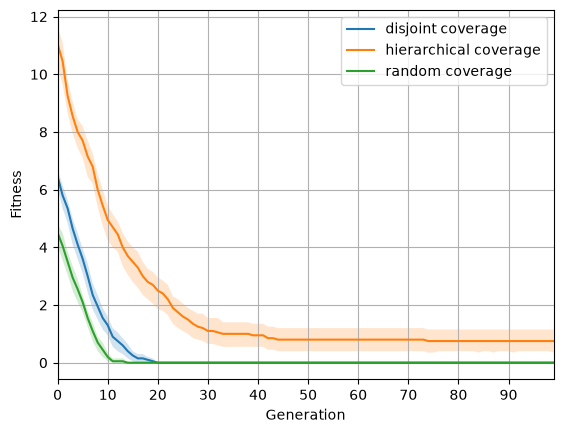

In [ ]:
plot_mean_and_bootstrapped_ci_over_time(
    data=results["fitness"],
    name="fitness",
    x_label="Generation",
    y_label="Fitness")

### Checking the genotypes

For hierarchical and random releases, there is usually an advantage in subtracting, not just adding. Let's see if that's happening, as a sanity check.

In [ ]:
results["solution"]["disjoint coverage"][-1]

array([[1., 0., 0., ..., 0., 1., 0.],
       [1., 0., 0., ..., 0., 1., 0.],
       [1., 0., 0., ..., 0., 1., 0.],
       ...,
       [1., 0., 0., ..., 0., 1., 0.],
       [1., 0., 0., ..., 0., 1., 0.],
       [1., 0., 0., ..., 0., 1., 0.]], shape=(100, 16))

In [ ]:
for name, experiment in results["solution"].items():
    last_genomes = list(ite.chain.from_iterable(experiment[-1]))
    cnt_plus = sum(1 for gene in last_genomes if gene == 1)
    cnt_no = sum(1 for gene in last_genomes if gene == 0)
    cnt_minus = sum(1 for gene in last_genomes if gene == -1)
    print(f"{name}: +1: {cnt_plus}, 0: {cnt_no}, -1: {cnt_minus}")

disjoint coverage: +1: 514, 0: 1086, -1: 0
hierarchical coverage: +1: 830, 0: 1716, -1: 554
random coverage: +1: 703, 0: 694, -1: 203
